<a href="https://colab.research.google.com/github/Junpyodo/brain_tumor_classification/blob/main/Brain_Tumor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# 뇌종양 분류(Brain Tumor Classification) 모델 개발

이 노트북에서는 뇌종양 MRI 이미지를 분류하는 딥러닝 모델을 구축합니다.
```

In [ ]:
#환경설정
import numpy as np
import matplotlib.pyplot as plt
import os
import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)
# GPU 사용 가능 여부 확인
print("GPU Available:", tf.config.list_physical_devices('GPU'))

In [ ]:
# 허깅페이스 datasets 라이브러리 설치 (낮은버전으로함)
!pip install "datasets<4.0.0"

In [ ]:
import datasets

#잘됐나 확인
print(datasets.__version__)

3.6.0


In [ ]:
# 데이터셋 빌더 다운 (처음에 HuggingFace에서 데이터 다운로드)
from datasets import load_dataset_builder
ds_builder = load_dataset_builder("PranomVignesh/MRI-Images-of-Brain-Tumor")

# feature 확인
ds_builder.info.features

# split data 지정
from datasets import get_dataset_split_names

get_dataset_split_names("PranomVignesh/MRI-Images-of-Brain-Tumor")
# 문서 기준으로는 ['train', 'validation', 'test']가 나와야 합니다.

# split 지정해서 로드 (Dataset 객체 반환)
from datasets import load_dataset

# 나눠서 저장
train_dataset = load_dataset("PranomVignesh/MRI-Images-of-Brain-Tumor", split="train")
train_dataset
val_dataset = load_dataset("PranomVignesh/MRI-Images-of-Brain-Tumor", split="validation")
val_dataset
test_dataset = load_dataset("PranomVignesh/MRI-Images-of-Brain-Tumor", split="test")
test_dataset

Resolving data files:   0%|          | 0/3759 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1073 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/537 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/3759 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1073 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/537 [00:00<?, ?it/s]

... (6 outputs left out)

Resolving data files:   0%|          | 0/3759 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1073 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/537 [00:00<?, ?it/s]

Dataset({
    features: ['image', 'label'],
    num_rows: 537
})

In [ ]:
# 다운로드한 데이터셋을 구글 드라이브에 저장 (처음에 함)
from datasets import load_dataset

dataset = load_dataset("PranomVignesh/MRI-Images-of-Brain-Tumor")
dataset.save_to_disk("/content/drive/MyDrive/brain_tumor")

KeyboardInterrupt: 

In [ ]:
#드라이브에 저장잘됐나 확인
import os
print(os.listdir("/content/drive/MyDrive/brain_tumor"))

['dataset_dict.json', 'train', 'validation', 'test']


In [ ]:
# 새 세션일때 다시 마운트 하기 (드라이브랑 경로 연결)
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 새 세션일때 불러오기 (확인용)
from datasets import load_from_disk

dataset = load_from_disk("/content/drive/MyDrive/brain_tumor")
dataset

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 3759
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 1073
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 537
    })
})

['glioma', 'meningioma', 'no-tumor', 'pituitary']
train {'glioma': 921, 'meningioma': 882, 'no-tumor': 915, 'pituitary': 1041}
validation {'glioma': 255, 'meningioma': 245, 'no-tumor': 282, 'pituitary': 291}
test {'glioma': 145, 'meningioma': 123, 'no-tumor': 115, 'pituitary': 154}


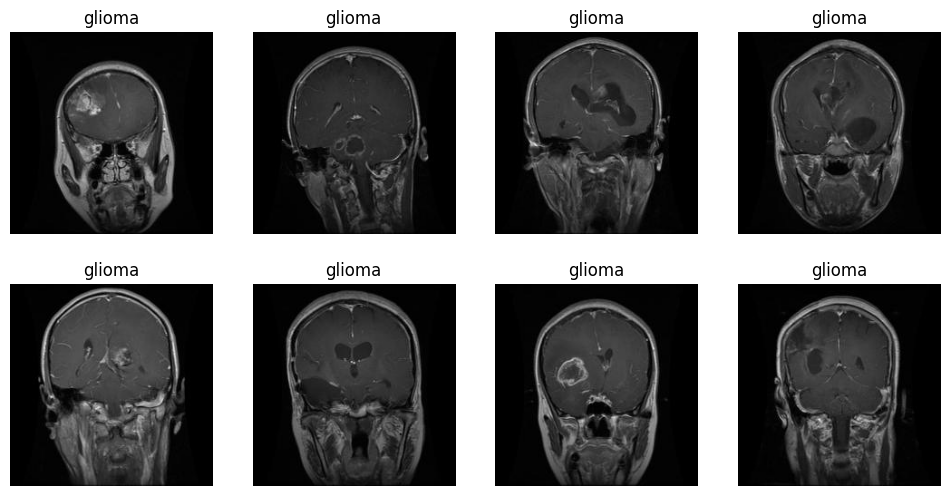

In [ ]:
# 데이터 확인용 셀
from collections import Counter
import matplotlib.pyplot as plt
from datasets import load_from_disk

# Drive에 저장해 둔 데이터셋 불러오기 (Drive 마운트가 되어 있어야 함)
dataset = load_from_disk("/content/drive/MyDrive/brain_tumor")
train_dataset = dataset["train"]
val_dataset = dataset["validation"]
test_dataset = dataset["test"]

# 라벨 이름
label_names = train_dataset.features["label"].names
print(label_names)

# split별 클래스 개수
for name, ds in [("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)]:
    counts = Counter(ds["label"])
    print(name, {label_names[k]: v for k, v in sorted(counts.items())})

# 이미지 샘플 8장 show()
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, example in zip(axes.flat, train_dataset.select(range(8))):
    ax.imshow(example["image"], cmap="gray")
    ax.set_title(label_names[example["label"]])
    ax.axis("off")
plt.show()

In [ ]:
# 데이터 전처리
import numpy as np
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

num_classes = len(label_names)

def to_tf_dataset(ds, training=False):
    def gen():
        for ex in ds:
            img = ex["image"].convert("RGB").resize(IMG_SIZE)  # 흑백도 3채널로
            yield np.asarray(img, dtype=np.uint8), ex["label"]

    tfds = tf.data.Dataset.from_generator(
        gen,
        output_signature=(
            tf.TensorSpec(shape=(*IMG_SIZE, 3), dtype=tf.uint8),
            tf.TensorSpec(shape=(), dtype=tf.int64),
        ),
    )
    tfds = tfds.cache()   # 메모리가 부족하면 이 줄을 삭제
    if training:
        tfds = tfds.shuffle(len(ds))   # shuffle(1000) 대신
    return tfds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = to_tf_dataset(train_dataset, training=True)
val_ds = to_tf_dataset(val_dataset)
test_ds = to_tf_dataset(test_dataset)

# 배치 하나 확인
for images, labels in train_ds.take(1):
    print(images.shape, images.dtype)   # (32, 224, 224, 3) uint8
    print(labels.shape, labels[:5].numpy())

(32, 224, 224, 3) <dtype: 'uint8'>
(32,) [1 3 2 1 0]


In [ ]:
# 데이터 증강 및 EfficientNet
from tensorflow.keras import layers

# 증강 (RandomFlip 제외, 학습할 때만 적용됨)
augment = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
], name="augment")

# EfficientNetB0는 0~255 입력을 받아 내부에서 정규화하므로 Rescaling 불필요
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(*IMG_SIZE, 3),
)
base_model.trainable = False   # 1단계: 분류 헤드만 학습

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = augment(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
# 1단계: 헤드만 학습
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history1 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=[early_stop])


Epoch 1/10
    118/Unknown 25s 74ms/step - accuracy: 0.6896 - loss: 0.8224

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


118/118 ━━━━━━━━━━━━━━━━━━━━ 33s 147ms/step - accuracy: 0.8127 - loss: 0.5606 - val_accuracy: 0.8863 - val_loss: 0.3395
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 11s 97ms/step - accuracy: 0.9117 - loss: 0.2846 - val_accuracy: 0.9087 - val_loss: 0.2734
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 11s 96ms/step - accuracy: 0.9311 - loss: 0.2176 - val_accuracy: 0.9282 - val_loss: 0.2277
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 11s 95ms/step - accuracy: 0.9354 - loss: 0.1979 - val_accuracy: 0.9254 - val_loss: 0.2134
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 11s 94ms/step - accuracy: 0.9423 - loss: 0.1813 - val_accuracy: 0.9273 - val_loss: 0.2025
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 12s 98ms/step - accuracy: 0.9436 - loss: 0.1655 - val_accuracy: 0.9357 - val_loss: 0.1857
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 11s 95ms/step - accuracy: 0.9481 - loss: 0.1532 - val_accuracy: 0.9413 - val_loss: 0.1724
Epoch 8/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 20s 93ms/step - accuracy: 0.9516 - loss: 0.1519 - val_accura

In [ ]:
# 2단계: 상위 20개 층만 풀어서 낮은 학습률로 파인튜닝
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False   # BN은 고정

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
history2 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=[early_stop])

Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 26s 124ms/step - accuracy: 0.9542 - loss: 0.1349 - val_accuracy: 0.9478 - val_loss: 0.1553
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 12s 101ms/step - accuracy: 0.9585 - loss: 0.1276 - val_accuracy: 0.9441 - val_loss: 0.1618
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 12s 102ms/step - accuracy: 0.9585 - loss: 0.1145 - val_accuracy: 0.9525 - val_loss: 0.1372
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 12s 102ms/step - accuracy: 0.9636 - loss: 0.1089 - val_accuracy: 0.9581 - val_loss: 0.1272
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 12s 100ms/step - accuracy: 0.9662 - loss: 0.1077 - val_accuracy: 0.9543 - val_loss: 0.1320
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 12s 100ms/step - accuracy: 0.9641 - loss: 0.1013 - val_accuracy: 0.9534 - val_loss: 0.1367
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 12s 100ms/step - accuracy: 0.9641 - loss: 0.1017 - val_accuracy: 0.9627 - val_loss: 0.1180
Epoch 8/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 12s 99ms/step - accuracy: 0.9683 - loss: 0.

In [ ]:
# 마지막에 사용한 테스트셋 및 PR Report
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# 최종 test 평가 (test는 이번에 한 번만 사용)
test_loss, test_acc = model.evaluate(test_ds)
print("test loss:", test_loss, "test acc:", test_acc)

# 클래스별 성능
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

# PR Report
print(classification_report(y_true, y_pred, target_names=label_names))
print(confusion_matrix(y_true, y_pred))

17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 223ms/step - accuracy: 0.9460 - loss: 0.1477
test loss: 0.14773070812225342 test acc: 0.9459962844848633
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 198ms/step
              precision    recall  f1-score   support

      glioma       1.00      0.99      0.99       145
  meningioma       0.93      0.83      0.88       123
    no-tumor       0.96      0.98      0.97       115
   pituitary       0.90      0.97      0.94       154

    accuracy                           0.95       537
   macro avg       0.95      0.94      0.94       537
weighted avg       0.95      0.95      0.95       537

[[143   2   0   0]
 [  0 102   5  16]
 [  0   2 113   0]
 [  0   4   0 150]]
